<a href="https://colab.research.google.com/github/TharushiSamarawickrama/DeepLearning_Lab/blob/main/Lab_07_Part_02_Q2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
# Imports
import gymnasium as gym
import random, math
import numpy as np
from collections import deque
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [19]:
#  Q-Network
class QNetwork(nn.Module):
    def __init__(self, state_dim, action_dim, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, action_dim),
        )
    def forward(self, x):
        return self.net(x)


In [20]:
#  Replay Buffer
class ReplayBuffer:
    def __init__(self, capacity=100_000):
        self.buf = deque(maxlen=capacity)
    def push(self, s, a, r, s2, d):
        self.buf.append((s, a, r, s2, d))
    def sample(self, batch_size):
        batch = random.sample(self.buf, batch_size)
        s, a, r, s2, d = map(np.array, zip(*batch))
        return s, a, r, s2, d
    def __len__(self):
        return len(self.buf)


In [21]:
#  DQN Agent (online + optional target, optional replay)
class DQNAgent:
    def __init__(
        self,
        state_dim,
        action_dim,
        lr=1e-3,
        gamma=0.99,
        batch_size=64,
        use_replay=True,
        use_target=True,
        eps_start=1.0,
        eps_end=0.01,
        eps_decay=0.995,
        device=None,
    ):
        self.state_dim = state_dim
        self.action_dim = action_dim
        self.gamma = gamma
        self.batch_size = batch_size
        self.use_replay = use_replay
        self.use_target = use_target
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")

        self.policy_net = QNetwork(state_dim, action_dim).to(self.device)
        self.target_net = QNetwork(state_dim, action_dim).to(self.device)
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.target_net.eval()

        self.opt = optim.Adam(self.policy_net.parameters(), lr=lr)
        self.loss_fn = nn.MSELoss()
        self.replay = ReplayBuffer() if use_replay else None

        # epsilon schedule
        self.epsilon = eps_start
        self.eps_min = eps_end
        self.eps_decay = eps_decay

    def choose_action(self, state):
        if random.random() < self.epsilon:
            return random.randrange(self.action_dim)
        with torch.no_grad():
            s = torch.tensor(state, dtype=torch.float32, device=self.device).unsqueeze(0)
            q = self.policy_net(s)
            return int(torch.argmax(q))

    def remember(self, s, a, r, s2, d):
        if self.use_replay:
            self.replay.push(s, a, r, s2, d)

    def learn(self, s, a, r, s2, d):
        """Returns loss value if an update happened, else None."""
        if self.use_replay:
            if len(self.replay) < self.batch_size:
                return None
            states, actions, rewards, next_states, dones = self.replay.sample(self.batch_size)
            states = torch.tensor(states, dtype=torch.float32, device=self.device)
            actions = torch.tensor(actions, dtype=torch.long, device=self.device).unsqueeze(1)
            rewards = torch.tensor(rewards, dtype=torch.float32, device=self.device).unsqueeze(1)
            next_states = torch.tensor(next_states, dtype=torch.float32, device=self.device)
            dones = torch.tensor(dones, dtype=torch.float32, device=self.device).unsqueeze(1)
        else:
            states = torch.tensor([s], dtype=torch.float32, device=self.device)
            actions = torch.tensor([[a]], dtype=torch.long, device=self.device)
            rewards = torch.tensor([[r]], dtype=torch.float32, device=self.device)
            next_states = torch.tensor([s2], dtype=torch.float32, device=self.device)
            dones = torch.tensor([[float(d)]], dtype=torch.float32, device=self.device)

        # Q(s,a)
        q_sa = self.policy_net(states).gather(1, actions)

        # Target: r + gamma * max_a' Q_target(s', a') * (1 - done)
        with torch.no_grad():
            q_next = (self.target_net if self.use_target else self.policy_net)(next_states).max(1, keepdim=True)[0]
            target = rewards + (1 - dones) * self.gamma * q_next

        loss = self.loss_fn(q_sa, target)
        self.opt.zero_grad()
        loss.backward()
        self.opt.step()
        return float(loss.item())

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon * self.eps_decay, self.eps_min)

    def sync_target(self):
        self.target_net.load_state_dict(self.policy_net.state_dict())

In [22]:
#  Training Helper
def train_dqn_on_lunar(
    num_episodes=500,
    target_update_steps=1000,
    use_replay=True,
    use_target=True,
    seed=0
):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

    env = gym.make("LunarLander-v3") # Updated to v3
    state_dim = env.observation_space.shape[0]   # 8
    action_dim = env.action_space.n              # 4

    agent = DQNAgent(
        state_dim, action_dim,
        lr=1e-3, gamma=0.99, batch_size=64,
        use_replay=use_replay, use_target=use_target,
        eps_start=1.0, eps_end=0.01, eps_decay=0.995
    )

    ep_rewards, ep_losses, epsilons = [], [], []
    step_losses = []   # optional fine-grained loss
    steps = 0

    for ep in range(num_episodes):
        state, _ = env.reset(seed=seed)
        done = False
        total_r = 0.0
        losses_this_ep = []

        while not done:
            action = agent.choose_action(state)
            next_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            agent.remember(state, action, reward, next_state, done)
            loss_val = agent.learn(state, action, reward, next_state, done)
            if loss_val is not None:
                losses_this_ep.append(loss_val)
                step_losses.append(loss_val)

            state = next_state
            total_r += reward
            steps += 1

            if use_target and steps % target_update_steps == 0:
                agent.sync_target()

        agent.decay_epsilon()
        ep_rewards.append(total_r)
        ep_losses.append(np.mean(losses_this_ep) if losses_this_ep else 0.0)
        epsilons.append(agent.epsilon)

        print(f"Ep {ep+1}/{num_episodes} | Reward {total_r:.1f} | Eps {agent.epsilon:.3f} | "
              f"Loss {ep_losses[-1]:.4f} | Steps {steps}")

    env.close()
    return {
        "rewards": np.array(ep_rewards),
        "mean_loss": np.array(ep_losses),
        "epsilons": np.array(epsilons),
        "step_losses": np.array(step_losses),
    }


In [27]:
#  Run: Full DQN (replay + target) AND Ablation (no replay, no target)
NUM_EPISODES = 500
TARGET_UPDATE_STEPS = 1000

logs_full = train_dqn_on_lunar(
    num_episodes=NUM_EPISODES,
    target_update_steps=TARGET_UPDATE_STEPS,
    use_replay=True,
    use_target=True,
    seed=42
)

logs_no = train_dqn_on_lunar(
    num_episodes=NUM_EPISODES,
    target_update_steps=TARGET_UPDATE_STEPS,   # ignored when use_target=False
    use_replay=False,
    use_target=False,
    seed=42
)


<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyPacked has no __module__ attribute
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyObject has no __module__ attribute
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type swigvarlink has no __module__ attribute
/usr/local/lib/python3.12/dist-packages/pygame/pkgdata.py:25: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import resource_stream, resource_exists
/usr/local/lib/python3.12/dist-packages/pkg_resources/__init__.py:3154: DeprecationWarning: Deprecated call to `pkg_resources.declare_namespace('google')`.
Implementing implicit namespace packages (as specified in PEP 420) is preferred to `pkg_resources.declare_namespace`. See https://setuptools.pypa.io/en/latest/references/keywords.html#keyword-namespace-packages
  declare_namespace(pkg)
/usr/local/lib/python3.12/dist-packages/

Ep 1/500 | Reward -196.8 | Eps 0.995 | Loss 4.6705 | Steps 114


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Ep 2/500 | Reward -345.7 | Eps 0.990 | Loss 63.7710 | Steps 223
Ep 3/500 | Reward -245.1 | Eps 0.985 | Loss 47.2812 | Steps 326
Ep 4/500 | Reward -159.6 | Eps 0.980 | Loss 47.4260 | Steps 448
Ep 5/500 | Reward -134.3 | Eps 0.975 | Loss 43.8239 | Steps 544
Ep 6/500 | Reward -358.7 | Eps 0.970 | Loss 39.9009 | Steps 677
Ep 7/500 | Reward -447.4 | Eps 0.966 | Loss 30.8963 | Steps 805
Ep 8/500 | Reward -88.9 | Eps 0.961 | Loss 39.3081 | Steps 924
Ep 9/500 | Reward -121.7 | Eps 0.956 | Loss 33.7431 | Steps 1031
Ep 10/500 | Reward -51.0 | Eps 0.951 | Loss 29.9526 | Steps 1158
Ep 11/500 | Reward -241.5 | Eps 0.946 | Loss 32.4410 | Steps 1263
Ep 12/500 | Reward -74.3 | Eps 0.942 | Loss 22.0643 | Steps 1370
Ep 13/500 | Reward -339.9 | Eps 0.937 | Loss 23.7087 | Steps 1493
Ep 14/500 | Reward -89.3 | Eps 0.932 | Loss 30.7176 | Steps 1608
Ep 15/500 | Reward -121.5 | Eps 0.928 | Loss 26.2054 | Steps 1723
Ep 16/500 | Reward -65.7 | Eps 0.923 | Loss 24.8783 | Steps 1840
Ep 17/500 | Reward -192.0 | Ep

/tmp/ipython-input-197660683.py:63: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  states = torch.tensor([s], dtype=torch.float32, device=self.device)


Ep 1/500 | Reward -158.9 | Eps 0.995 | Loss 91.3725 | Steps 110
Ep 2/500 | Reward -202.7 | Eps 0.990 | Loss 119.7065 | Steps 221
Ep 3/500 | Reward -432.5 | Eps 0.985 | Loss 86.3431 | Steps 331
Ep 4/500 | Reward -298.0 | Eps 0.980 | Loss 64.0303 | Steps 440
Ep 5/500 | Reward -285.0 | Eps 0.975 | Loss 101.7124 | Steps 575
Ep 6/500 | Reward -313.6 | Eps 0.970 | Loss 39.0243 | Steps 690
Ep 7/500 | Reward -387.7 | Eps 0.966 | Loss 106.8554 | Steps 802
Ep 8/500 | Reward -139.0 | Eps 0.961 | Loss 41.6477 | Steps 940
Ep 9/500 | Reward -127.7 | Eps 0.956 | Loss 44.5883 | Steps 1052
Ep 10/500 | Reward -288.9 | Eps 0.951 | Loss 8.3164 | Steps 1156
Ep 11/500 | Reward -84.8 | Eps 0.946 | Loss 50.2740 | Steps 1269
Ep 12/500 | Reward -149.2 | Eps 0.942 | Loss 40.4468 | Steps 1382
Ep 13/500 | Reward -123.2 | Eps 0.937 | Loss 40.0502 | Steps 1510
Ep 14/500 | Reward -376.2 | Eps 0.932 | Loss 63.2907 | Steps 1628
Ep 15/500 | Reward -84.5 | Eps 0.928 | Loss 49.0946 | Steps 1751
Ep 16/500 | Reward -490.6 |

In [26]:
!pip install swig
!pip install "gymnasium[box2d]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 19.3 MB/s eta 0:00:00
  Using cached box2d-py-2.3.5.tar.gz (374 kB)
  Preparing metadata (setup.py) ... done
  Created wheel for box2d-py: filename=box2d_py-2.3.5-cp312-cp312-linux_x86_64.whl size=2409532 sha256=9b9afaece902104ce4d757cdd1bae0b0cf18fcbdf30934e99c8334e497526588
  Stored in directory: /root/.cache/pip/wheels/2a/e9/60/774da0bcd07f7dc7761a8590fa2d065e4069568e78dcdc3318
Successfully built box2d-py


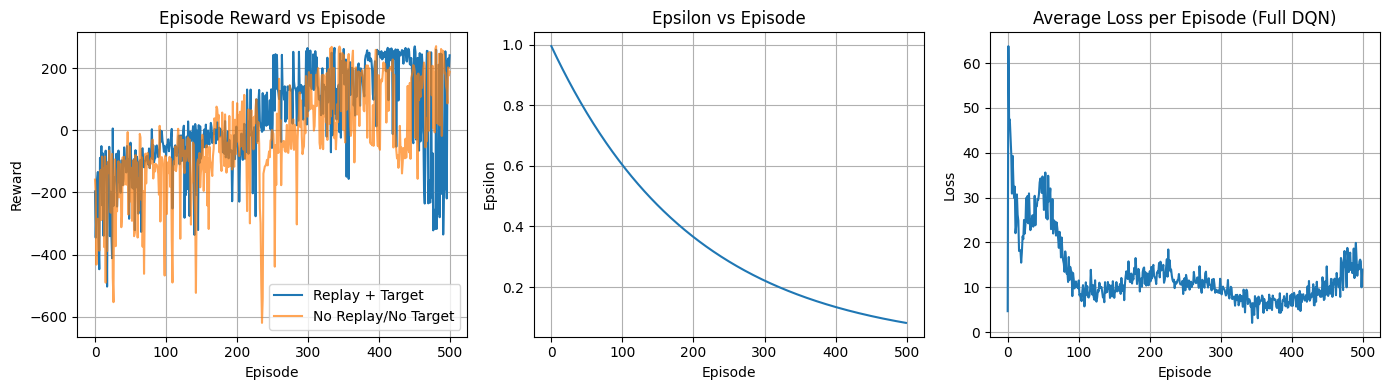

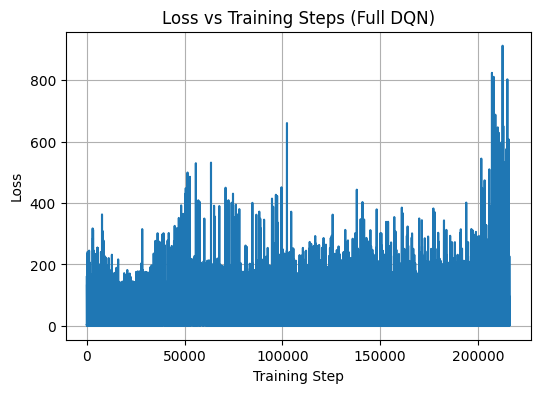

In [28]:
# ===== Plots =====
plt.figure(figsize=(14,4))

# Episode reward
plt.subplot(1,3,1)
plt.plot(logs_full["rewards"], label="Replay + Target")
plt.plot(logs_no["rewards"],   label="No Replay/No Target", alpha=0.7)
plt.title("Episode Reward vs Episode")
plt.xlabel("Episode"); plt.ylabel("Reward"); plt.legend(); plt.grid(True)

# Epsilon
plt.subplot(1,3,2)
plt.plot(logs_full["epsilons"])
plt.title("Epsilon vs Episode")
plt.xlabel("Episode"); plt.ylabel("Epsilon"); plt.grid(True)

# Loss
plt.subplot(1,3,3)
plt.plot(logs_full["mean_loss"])
plt.title("Average Loss per Episode (Full DQN)")
plt.xlabel("Episode"); plt.ylabel("Loss"); plt.grid(True)

plt.tight_layout()
plt.show()

# Optional: Loss vs training steps (finer-grained)
plt.figure(figsize=(6,4))
plt.plot(logs_full["step_losses"])
plt.title("Loss vs Training Steps (Full DQN)")
plt.xlabel("Training Step"); plt.ylabel("Loss"); plt.grid(True)
plt.show()
